# 03 — PPG-Only Deep Learning Baseline

This notebook trains the first Deep Learning baseline for heart-rate estimation.

## Input
- Raw PPG only
- shape: `(N, 320, 1)`
- every sample represents exactly 8 seconds

## Target
- Mean chest-strap heart rate inside the same 8-second window

## Important
- Activity labels are **not** used as model inputs.
- Watch HR is **not** used as a model input.
- Normalization parameters are calculated from the **training set only**.
- Validation and test data are never used to calculate normalization statistics.
- Nothing is saved to disk in this notebook.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Re-run the Final Preprocessing Pipeline

This executes `02_preprocessing_windowing.ipynb` in the same notebook namespace.

It recreates:
- `X_ppg_train`, `X_ppg_val`, `X_ppg_test`
- `y_train`, `y_val`, `y_test`
- `meta_train`, `meta_val`, `meta_test`

The preprocessing notebook itself does not save files.

In [3]:
%%capture preprocessing_output
%run ./02_preprocessing_windowing.ipynb

## 3. Confirm Input Shapes

In [4]:
print("Train:", X_ppg_train.shape, y_train.shape)
print("Val  :", X_ppg_val.shape, y_val.shape)
print("Test :", X_ppg_test.shape, y_test.shape)

assert X_ppg_train.shape[1:] == (320, 1)
assert X_ppg_val.shape[1:] == (320, 1)
assert X_ppg_test.shape[1:] == (320, 1)

print("PPG-only input shapes are correct.")

Train: (1322, 320, 1) (1322,)
Val  : (281, 320, 1) (281,)
Test : (292, 320, 1) (292,)
PPG-only input shapes are correct.


## 4. Training-Only Normalization

A global z-score normalization is used for the PPG baseline:

`PPG_norm = (PPG - train_mean) / train_std`

The mean and standard deviation are calculated **only from `X_ppg_train`**.
The same training statistics are then applied to validation and test inputs.

In [5]:
ppg_train_mean = float(
    X_ppg_train.mean()
)

ppg_train_std = float(
    X_ppg_train.std()
)

if ppg_train_std == 0:
    raise ValueError("Training PPG standard deviation is zero.")

X_train_norm = (
    X_ppg_train - ppg_train_mean
) / ppg_train_std

X_val_norm = (
    X_ppg_val - ppg_train_mean
) / ppg_train_std

X_test_norm = (
    X_ppg_test - ppg_train_mean
) / ppg_train_std

print(f"Train PPG mean: {ppg_train_mean:.4f}")
print(f"Train PPG std : {ppg_train_std:.4f}")

print()
print(
    "Normalized train mean:",
    float(X_train_norm.mean())
)

print(
    "Normalized train std :",
    float(X_train_norm.std())
)

Train PPG mean: 4475.9858
Train PPG std : 1247.3558

Normalized train mean: -1.777498823685164e-07
Normalized train std : 0.9999998807907104


## 5. Visual Check After Normalization

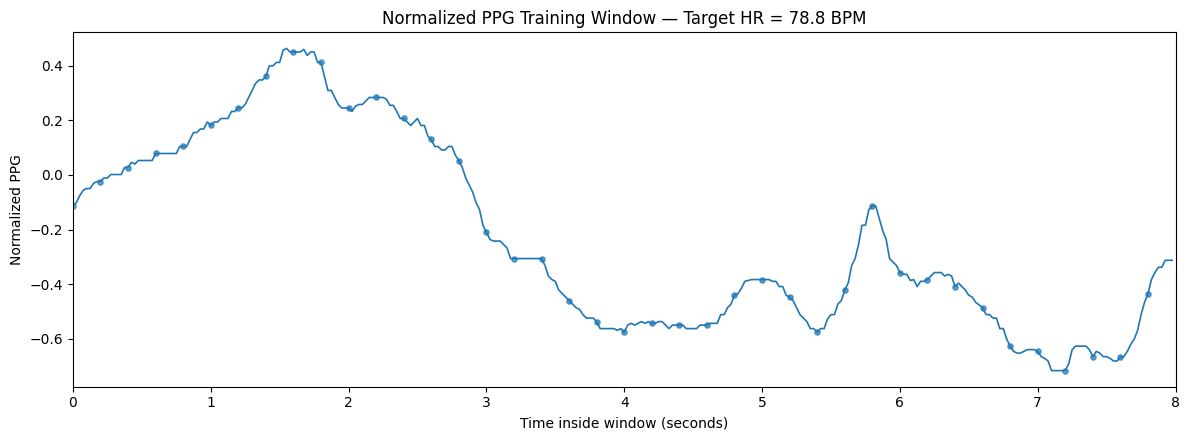

In [6]:
example_index = 0

time_axis = np.linspace(
    0,
    8,
    X_train_norm.shape[1],
    endpoint=False
)

plt.figure(figsize=(12, 4.5))

plt.plot(
    time_axis,
    X_train_norm[
        example_index,
        :,
        0
    ],
    linewidth=1.2
)

plt.scatter(
    time_axis[::8],
    X_train_norm[
        example_index,
        ::8,
        0
    ],
    s=14,
    alpha=0.7
)

plt.title(
    f"Normalized PPG Training Window — "
    f"Target HR = {y_train[example_index]:.1f} BPM"
)

plt.xlabel("Time inside window (seconds)")
plt.ylabel("Normalized PPG")
plt.xlim(0, 8)
plt.tight_layout()
plt.show()

## 6. Reproducibility

A fixed random seed is used so repeated runs are easier to compare.

In [7]:
SEED = 42

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

## 7. Build the 1D CNN

The model uses temporal convolutions to learn local waveform patterns from the 8-second PPG sequence.

Architecture:
- Conv1D
- Batch Normalization
- Max Pooling
- Conv1D
- Batch Normalization
- Max Pooling
- Conv1D
- Global Average Pooling
- Dense regression head

In [8]:
def build_ppg_model():
    inputs = tf.keras.layers.Input(
        shape=(320, 1),
        name="ppg_input"
    )

    x = tf.keras.layers.Conv1D(
        32,
        kernel_size=7,
        padding="same",
        activation="relu"
    )(inputs)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.MaxPooling1D(
        pool_size=2
    )(x)

    x = tf.keras.layers.Conv1D(
        64,
        kernel_size=5,
        padding="same",
        activation="relu"
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)

    x = tf.keras.layers.MaxPooling1D(
        pool_size=2
    )(x)

    x = tf.keras.layers.Conv1D(
        128,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    x = tf.keras.layers.GlobalAveragePooling1D()(x)

    x = tf.keras.layers.Dropout(
        0.30
    )(x)

    x = tf.keras.layers.Dense(
        64,
        activation="relu"
    )(x)

    x = tf.keras.layers.Dropout(
        0.20
    )(x)

    outputs = tf.keras.layers.Dense(
        1,
        name="predicted_hr"
    )(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="PPG_Only_1D_CNN"
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="mse",
        metrics=["mae"]
    )

    return model


model = build_ppg_model()
model.summary()

Model: "PPG_Only_1D_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ ppg_input (InputLayer)          │ (None, 320, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d (Conv1D)                 │ (None, 320, 32)        │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 320, 32)        │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 160, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 160, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 160, 64)        │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 80, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 80, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predicted_hr (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 43,969 (171.75 KB)

 Trainable params: 43,777 (171.00 KB)

 Non-trainable params: 192 (768.00 B)

## 8. Training Callbacks

In [9]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=18,
        restore_best_weights=True,
        verbose=1,
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=7,
        min_lr=1e-6,
        verbose=1,
    ),
]

## 9. Train the PPG-Only Model

Training uses:
- Train split for parameter learning
- Validation split for EarlyStopping and learning-rate reduction
- Test split remains untouched until final evaluation

In [10]:
history = model.fit(
    X_train_norm,
    y_train,

    validation_data=(
        X_val_norm,
        y_val
    ),

    epochs=180,
    batch_size=32,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 4801.3599 - mae: 60.7837 - val_loss: 6902.2773 - val_mae: 80.1316 - learning_rate: 0.0010
Epoch 2/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1083.8698 - mae: 26.7394 - val_loss: 6281.8604 - val_mae: 76.6690 - learning_rate: 0.0010
Epoch 3/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 937.2678 - mae: 25.1043 - val_loss: 5410.9224 - val_mae: 71.0601 - learning_rate: 0.0010
Epoch 4/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 873.9894 - mae: 24.3250 - val_loss: 4482.2026 - val_mae: 64.3249 - learning_rate: 0.0010
Epoch 5/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 842.4118 - mae: 23.9034 - val_loss: 3444.6545 - val_mae: 55.7345 - learning_rate: 0.0010
Epoch 6/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 874.7432 - mae: 24.5886 - val_loss: 2544.4094 - val_mae: 46.9014 - learning_rate: 0.0010
Epoch 7/180
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 812.1122 - mae: 23.8152 - val_loss: 2209.7029 - va

## 10. Training History

Epochs trained: 132
Best epoch    : 114


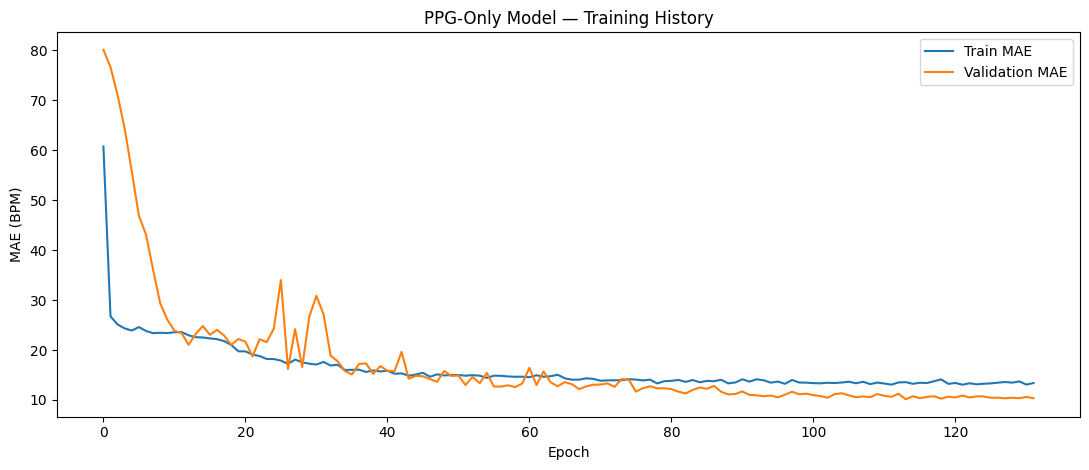

In [11]:
history_df = pd.DataFrame(
    history.history
)

best_epoch = int(
    history_df["val_loss"].idxmin()
    + 1
)

print("Epochs trained:", len(history_df))
print("Best epoch    :", best_epoch)

plt.figure(figsize=(11, 4.8))

plt.plot(
    history_df["mae"],
    label="Train MAE"
)

plt.plot(
    history_df["val_mae"],
    label="Validation MAE"
)

plt.xlabel("Epoch")
plt.ylabel("MAE (BPM)")
plt.title("PPG-Only Model — Training History")
plt.legend()
plt.tight_layout()
plt.show()

## 11. Test Predictions

In [12]:
y_pred = (
    model.predict(
        X_test_norm,
        verbose=0
    )
    .reshape(-1)
)

print("Predictions:", y_pred.shape)

Predictions: (292,)


## 12. Metric Function

In [13]:
def regression_metrics(
    y_true,
    y_prediction
):
    y_true = np.asarray(
        y_true,
        dtype=float
    )

    y_prediction = np.asarray(
        y_prediction,
        dtype=float
    )

    mae = mean_absolute_error(
        y_true,
        y_prediction
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true,
            y_prediction
        )
    )

    r2 = r2_score(
        y_true,
        y_prediction
    )

    if (
        len(y_true) > 1
        and np.std(y_true) > 0
        and np.std(y_prediction) > 0
    ):
        correlation = np.corrcoef(
            y_true,
            y_prediction
        )[0, 1]
    else:
        correlation = np.nan

    return {
        "MAE_BPM": mae,
        "RMSE_BPM": rmse,
        "R2": r2,
        "Correlation": correlation,
        "True_Mean": np.mean(y_true),
        "True_Std": np.std(y_true),
        "Pred_Mean": np.mean(y_prediction),
        "Pred_Std": np.std(y_prediction),
    }

## 13. Overall Test Metrics

In [14]:
overall_metrics = regression_metrics(
    y_test,
    y_pred
)

overall_results = pd.DataFrame([
    {
        "Model": "PPG-only 1D CNN",
        **overall_metrics,
    }
])

display(
    overall_results.round(3)
)

,Model,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,PPG-only 1D CNN,10.08,12.548,0.719,0.87,89.163,23.663,91.124,16.451


## 14. Global Mean Baseline

A simple reference baseline predicts the mean training HR for every test window.

The Deep Learning model should ideally outperform this baseline.

In [15]:
train_mean_hr = float(
    np.mean(y_train)
)

baseline_pred = np.full(
    shape=len(y_test),
    fill_value=train_mean_hr,
    dtype=float
)

baseline_metrics = regression_metrics(
    y_test,
    baseline_pred
)

comparison_df = pd.DataFrame([
    {
        "Model": "Train-mean baseline",
        **baseline_metrics,
    },
    {
        "Model": "PPG-only 1D CNN",
        **overall_metrics,
    },
])

display(
    comparison_df.round(3)
)

,Model,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Train-mean baseline,21.293,23.836,-0.015,NaN,89.163,23.663,92.031,0.000
1,PPG-only 1D CNN,10.080,12.548,0.719,0.87,89.163,23.663,91.124,16.451


## 15. Per-Activity Test Metrics

Overall metrics alone can be misleading because the activities have different HR ranges.

Therefore the model is also evaluated separately for each activity.

In [16]:
test_activity = (
    meta_test[
        "Activity"
    ]
    .to_numpy()
)

activity_rows = []

for activity in ACTIVITY_ORDER:
    mask = (
        test_activity
        == activity
    )

    if not np.any(mask):
        continue

    metrics = regression_metrics(
        y_test[mask],
        y_pred[mask]
    )

    activity_rows.append({
        "Activity": activity,
        "Test_Windows": int(
            mask.sum()
        ),
        **metrics,
    })


activity_results = pd.DataFrame(
    activity_rows
)

display(
    activity_results.round(3)
)

,Activity,Test_Windows,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Eating,8,14.266,20.413,-16.225,-0.190,84.915,4.918,98.904,13.127
1,High_Tempo_Cycling,38,12.673,16.136,-1.690,0.174,113.883,9.839,104.523,10.599
2,Low_Tempo_Cycling,56,10.601,12.631,-9.938,-0.112,112.126,3.819,103.267,7.737
3,Sitting,43,9.279,11.604,-1.687,0.556,72.895,7.079,81.520,9.002
4,Sleep,73,13.265,13.956,-122.253,0.207,56.056,1.257,69.321,4.420
5,Walking,74,5.224,7.171,-4.542,0.036,101.662,3.046,101.303,6.592


## 16. Macro Activity Metrics

In [17]:
macro_mae = float(
    activity_results[
        "MAE_BPM"
    ].mean()
)

macro_rmse = float(
    activity_results[
        "RMSE_BPM"
    ].mean()
)

macro_corr = float(
    activity_results[
        "Correlation"
    ].mean()
)

print(
    f"Macro activity MAE        : "
    f"{macro_mae:.3f} BPM"
)

print(
    f"Macro activity RMSE       : "
    f"{macro_rmse:.3f} BPM"
)

print(
    f"Macro activity correlation: "
    f"{macro_corr:.3f}"
)

Macro activity MAE        : 10.885 BPM
Macro activity RMSE       : 13.652 BPM
Macro activity correlation: 0.112


## 17. Ground Truth vs Prediction Over Test Windows

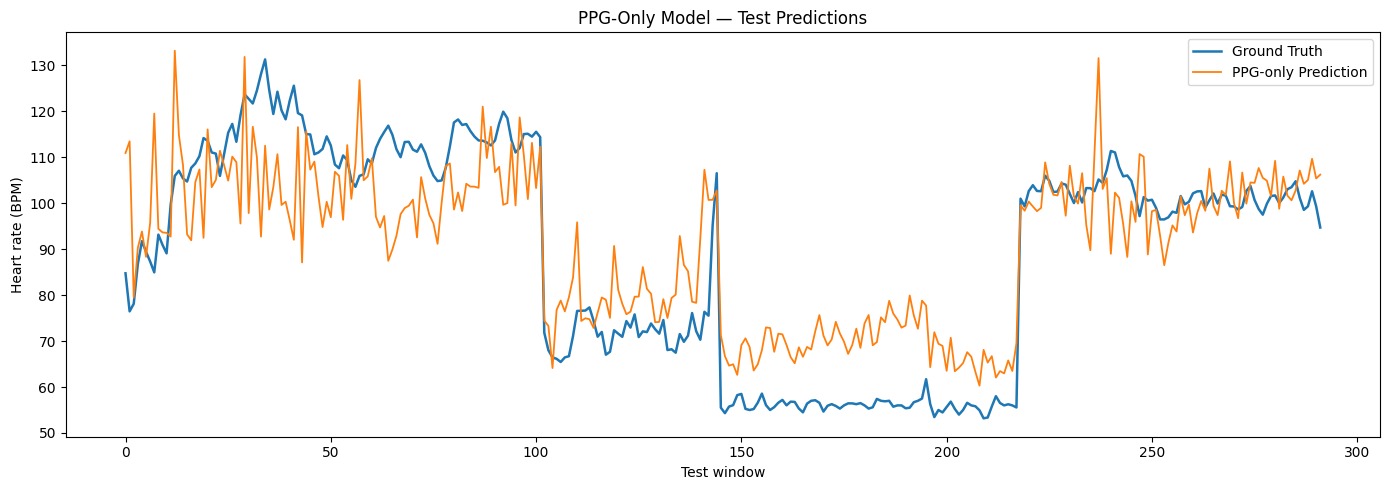

In [18]:
plt.figure(figsize=(14, 5))

plt.plot(
    y_test,
    label="Ground Truth",
    linewidth=1.8
)

plt.plot(
    y_pred,
    label="PPG-only Prediction",
    linewidth=1.3
)

plt.xlabel("Test window")
plt.ylabel("Heart rate (BPM)")
plt.title("PPG-Only Model — Test Predictions")
plt.legend()
plt.tight_layout()
plt.show()

## 18. Predicted vs True HR

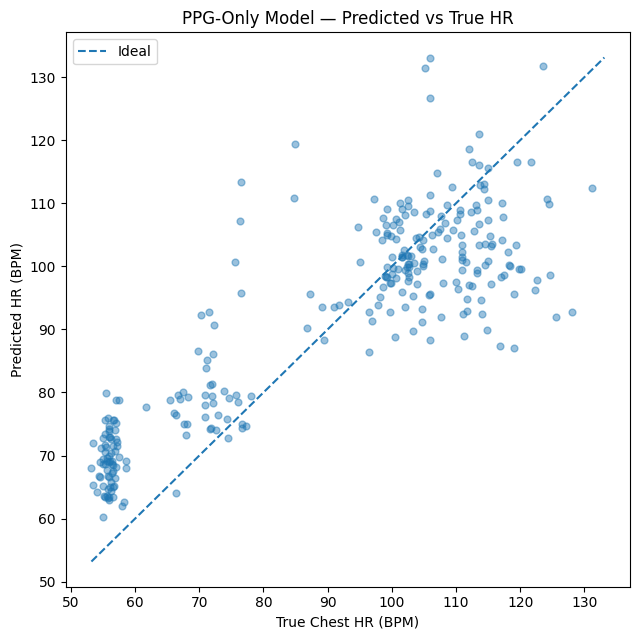

In [19]:
low = float(
    min(
        y_test.min(),
        y_pred.min()
    )
)

high = float(
    max(
        y_test.max(),
        y_pred.max()
    )
)

plt.figure(figsize=(6.5, 6.5))

plt.scatter(
    y_test,
    y_pred,
    s=24,
    alpha=0.45
)

plt.plot(
    [low, high],
    [low, high],
    linestyle="--",
    linewidth=1.5,
    label="Ideal"
)

plt.xlabel("True Chest HR (BPM)")
plt.ylabel("Predicted HR (BPM)")
plt.title("PPG-Only Model — Predicted vs True HR")
plt.legend()
plt.tight_layout()
plt.show()

## 19. Per-Activity MAE

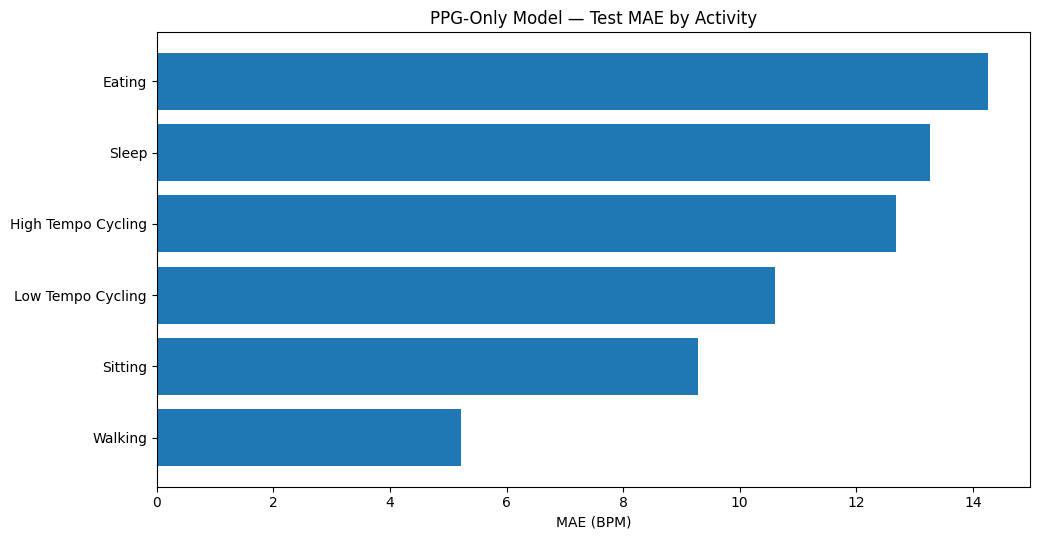

In [20]:
plot_df = activity_results.sort_values(
    "MAE_BPM"
)

plt.figure(figsize=(10.5, 5.5))

plt.barh(
    plot_df[
        "Activity"
    ].str.replace(
        "_",
        " "
    ),
    plot_df[
        "MAE_BPM"
    ]
)

plt.xlabel("MAE (BPM)")
plt.title("PPG-Only Model — Test MAE by Activity")
plt.tight_layout()
plt.show()

## 20. Per-Activity Correlation

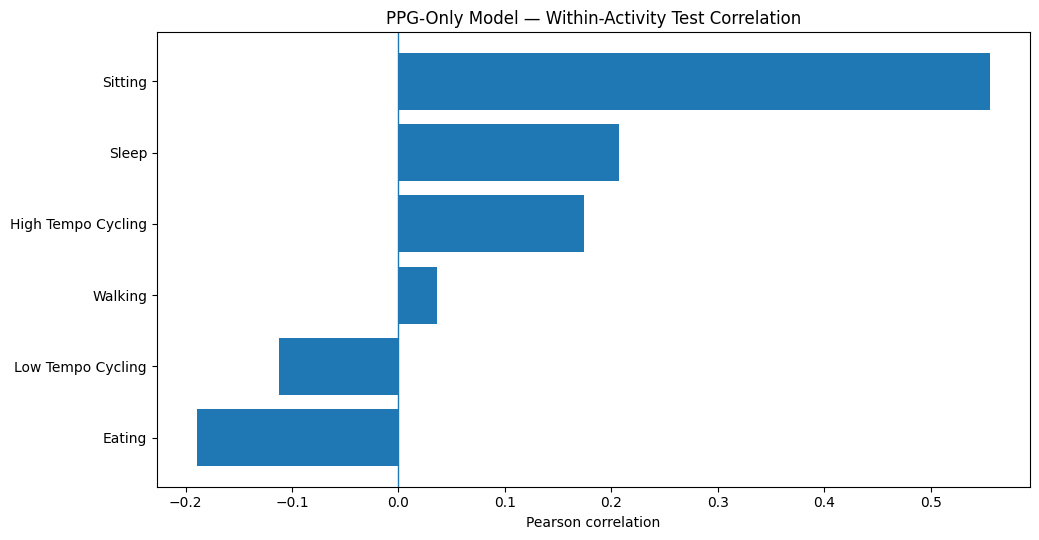

In [21]:
plot_df = activity_results.sort_values(
    "Correlation"
)

plt.figure(figsize=(10.5, 5.5))

plt.barh(
    plot_df[
        "Activity"
    ].str.replace(
        "_",
        " "
    ),
    plot_df[
        "Correlation"
    ]
)

plt.axvline(
    0,
    linewidth=1
)

plt.xlabel("Pearson correlation")
plt.title(
    "PPG-Only Model — Within-Activity Test Correlation"
)

plt.tight_layout()
plt.show()

## 21. No Saving

This experiment intentionally saves nothing.

The notebook does **not** write:
- model files,
- CSV metrics,
- prediction files,
- PNG figures,
- processed arrays.

Results are kept only in notebook memory/output until the final pipeline is selected.

## 22. What to Send for Review

After running this notebook, send:

1. `Overall Test Metrics`
2. `Train-mean baseline vs PPG-only`
3. `Per-Activity Test Metrics`
4. Training-history graph
5. Ground-truth vs prediction graph
6. Per-activity correlation graph

Then we can decide whether this is a suitable PPG-only baseline before building the PPG+ACC fusion model.

Training HR mean by activity:


,Activity,Train_Mean_HR_BPM
0,Eating,83.854
1,High_Tempo_Cycling,123.844
2,Low_Tempo_Cycling,114.600
3,Sitting,75.909
4,Sleep,58.850
5,Walking,101.992


Overall diagnostic comparison:


,Model,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Global train-mean baseline,21.293,23.836,-0.015,NaN,89.163,23.663,92.031,0.000
1,Activity-mean baseline,4.316,6.604,0.922,0.969,89.163,23.663,92.130,23.872
2,PPG-only 1D CNN,10.080,12.548,0.719,0.870,89.163,23.663,91.124,16.451


Activity-mean baseline — per activity:


,Activity,Test_Windows,MAE_BPM,RMSE_BPM,R2,Correlation,True_Mean,True_Std,Pred_Mean,Pred_Std
0,Eating,8,4.353,5.032,-0.047,NaN,84.915,4.918,83.854,0.0
1,High_Tempo_Cycling,38,10.750,14.000,-1.025,NaN,113.883,9.839,123.844,0.0
2,Low_Tempo_Cycling,56,3.521,4.550,-0.419,NaN,112.126,3.819,114.600,0.0
3,Sitting,43,5.516,7.694,-0.181,NaN,72.895,7.079,75.909,0.0
4,Sleep,73,2.872,3.064,-4.939,NaN,56.056,1.257,58.850,0.0
5,Walking,74,2.336,3.064,-0.012,NaN,101.662,3.046,101.992,0.0


Direct per-activity MAE comparison:


,Activity,Activity_Mean_MAE,PPG_CNN_MAE,CNN_Improvement_BPM
0,Eating,4.353,14.266,-9.913
1,High_Tempo_Cycling,10.750,12.673,-1.923
2,Low_Tempo_Cycling,3.521,10.601,-7.080
3,Sitting,5.516,9.279,-3.764
4,Sleep,2.872,13.265,-10.394
5,Walking,2.336,5.224,-2.888


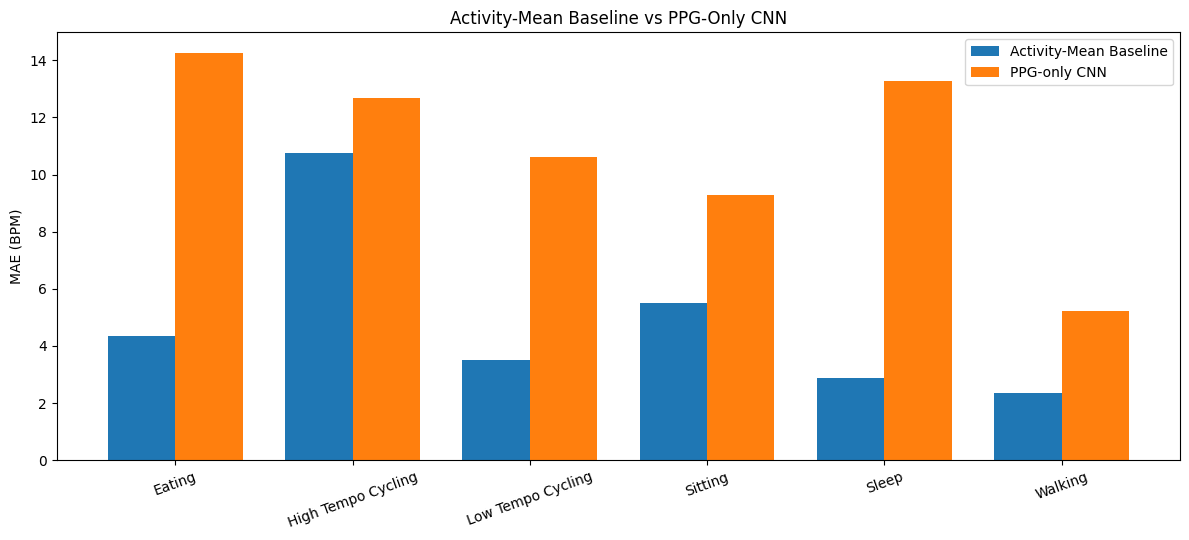

In [22]:
# ============================================================
# Activity-Mean Diagnostic Baseline
# ============================================================

train_activity = meta_train["Activity"].to_numpy()
test_activity = meta_test["Activity"].to_numpy()

# 1) Training set: mean HR for each activity
activity_mean_map = {}

for activity in ACTIVITY_ORDER:
    mask = train_activity == activity

    if np.any(mask):
        activity_mean_map[activity] = float(
            np.mean(y_train[mask])
        )

activity_mean_table = pd.DataFrame({
    "Activity": list(activity_mean_map.keys()),
    "Train_Mean_HR_BPM": list(activity_mean_map.values())
})

print("Training HR mean by activity:")
display(activity_mean_table.round(3))


# 2) Predict test HR using only the activity mean
activity_mean_pred = np.array(
    [
        activity_mean_map[activity]
        for activity in test_activity
    ],
    dtype=float
)


# 3) Overall metrics
activity_mean_metrics = regression_metrics(
    y_test,
    activity_mean_pred
)

overall_diagnostic = pd.DataFrame([
    {
        "Model": "Global train-mean baseline",
        **baseline_metrics
    },
    {
        "Model": "Activity-mean baseline",
        **activity_mean_metrics
    },
    {
        "Model": "PPG-only 1D CNN",
        **overall_metrics
    }
])

print("Overall diagnostic comparison:")
display(
    overall_diagnostic.round(3)
)


# 4) Per-activity metrics for the activity-mean baseline
activity_baseline_rows = []

for activity in ACTIVITY_ORDER:
    mask = test_activity == activity

    if not np.any(mask):
        continue

    metrics = regression_metrics(
        y_test[mask],
        activity_mean_pred[mask]
    )

    activity_baseline_rows.append({
        "Activity": activity,
        "Test_Windows": int(mask.sum()),
        **metrics
    })

activity_baseline_results = pd.DataFrame(
    activity_baseline_rows
)

print("Activity-mean baseline — per activity:")
display(
    activity_baseline_results.round(3)
)


# 5) Direct MAE comparison: Activity baseline vs CNN
mae_comparison = (
    activity_baseline_results[
        ["Activity", "MAE_BPM"]
    ]
    .rename(
        columns={
            "MAE_BPM": "Activity_Mean_MAE"
        }
    )
    .merge(
        activity_results[
            ["Activity", "MAE_BPM"]
        ].rename(
            columns={
                "MAE_BPM": "PPG_CNN_MAE"
            }
        ),
        on="Activity"
    )
)

mae_comparison["CNN_Improvement_BPM"] = (
    mae_comparison["Activity_Mean_MAE"]
    - mae_comparison["PPG_CNN_MAE"]
)

print("Direct per-activity MAE comparison:")
display(
    mae_comparison.round(3)
)


# 6) Visual comparison
x = np.arange(
    len(mae_comparison)
)

width = 0.38

plt.figure(
    figsize=(12, 5.5)
)

plt.bar(
    x - width / 2,
    mae_comparison["Activity_Mean_MAE"],
    width,
    label="Activity-Mean Baseline"
)

plt.bar(
    x + width / 2,
    mae_comparison["PPG_CNN_MAE"],
    width,
    label="PPG-only CNN"
)

plt.xticks(
    x,
    mae_comparison["Activity"].str.replace("_", " "),
    rotation=20
)

plt.ylabel("MAE (BPM)")
plt.title(
    "Activity-Mean Baseline vs PPG-Only CNN"
)

plt.legend()
plt.tight_layout()
plt.show()